*  DSC640-T302 Data Presentation & Visualizat (2267-1)
*  Weeks 1 & 2 Assignment - Netflix Viewership
*  David Jorgensen

# Films vs. TV: Where Netflix's Top 10 Demand Actually Lives

**Persona / Audience:** Internal content-strategy briefing for Netflix executives and board members.
**Purpose / Call to action:** Films win the splashy opening week, but *serialized TV, especially non-English TV, owns the long tail of engagement.* This notebook builds the evidence behind the recommendation to **shift a measurable slice of marginal content spend from one-off films toward returnable, non-English series.**

**Datasets used:**
1. `all-weeks-global-netflix.xlsx`: weekly global Top 10 (146 weeks, Jul 2021–Apr 2024) with hours, views, and weeks-in-Top-10.
2. `all-weeks-countries-netflix.xlsx`: weekly Top 10 for 94 countries (272k rows), geographic durability.
3. `most-popular-netflix.xlsx`: all-time most popular titles by first-91-day hours/views.


In [ ]:
# Libraries
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import font_manager
import warnings; warnings.filterwarnings("ignore")

# ---- Netflix-inspired theme ----
INK="#141414"; PANEL="#1f1f1f"; RED="#E50914"; GOLD="#F5C518"; GREY="#808080"; LIGHT="#E5E5E5"
FILM=GREY; TV=RED
plt.rcParams.update({
    "figure.facecolor":INK, "axes.facecolor":INK, "savefig.facecolor":INK,
    "text.color":LIGHT, "axes.labelcolor":LIGHT, "xtick.color":LIGHT, "ytick.color":LIGHT,
    "axes.edgecolor":"#3a3a3a", "axes.grid":True, "grid.color":"#2b2b2b", "grid.linewidth":.8,
    "font.size":11, "axes.titleweight":"bold", "axes.titlesize":14, "figure.dpi":120})
OUT="charts"; import os; os.makedirs(OUT, exist_ok=True)

In [ ]:
# Load data
g = pd.read_excel("data/all-weeks-global-netflix.xlsx")
c = pd.read_excel("data/all-weeks-countries-netflix.xlsx")
m = pd.read_excel("data/most-popular-netflix.xlsx")

# Add type and language columns
ftype = lambda x: "TV" if "TV" in x else "Film"
for d in (g, c, m): d["type"] = d["category"].map(ftype)
# Add language columns
g["lang"] = g.category.map(lambda x: "Non-English" if "Non-English" in x else "English")
m["lang"] = m.category.map(lambda x: "Non-English" if "Non-English" in x else "English")
# Convert week column to datetime
g["week"] = pd.to_datetime(g.week); c["week"] = pd.to_datetime(c.week)
# Display data information
print("Global:", g.shape, "| Countries:", c.shape, "| Most popular:", m.shape)
print("Weeks:", g.week.dt.date.min(), "->", g.week.dt.date.max(), "| Countries:", c.country_name.nunique())

Global: (5840, 13) | Countries: (272260, 9) | Most popular: (40, 9)
Weeks: 2021-07-04 -> 2024-04-14 | Countries: 94


## Cleaning & assumptions (logged for transparency)
- **Category collapse.** Netflix's four labels (Films/TV × English/Non-English) are mapped to a two-level `type` (Film vs TV) for the headline comparison; the language split is preserved separately so nothing is silently dropped.
- **Title-level durability.** "Weeks in Top 10" is cumulative and resets per title, so per-title staying power is taken as the **max** `cumulative_weeks_in_top_10` to avoid double counting weekly rows.
- **No rows filtered out.** All weeks and all 94 countries are retained. Missing `season_title`/`runtime` values are left as-is (not imputed).
- **Structural note.** Each country-week always contains 10 Film + 10 TV slots, so the *count* of slots is 50/50 by construction — we therefore measure **durability (weeks held)** and **reach (countries charted)**, never raw slot share, which would be a misleading metric.


### Visual 1 — Staying power distribution: TV outlasts Film

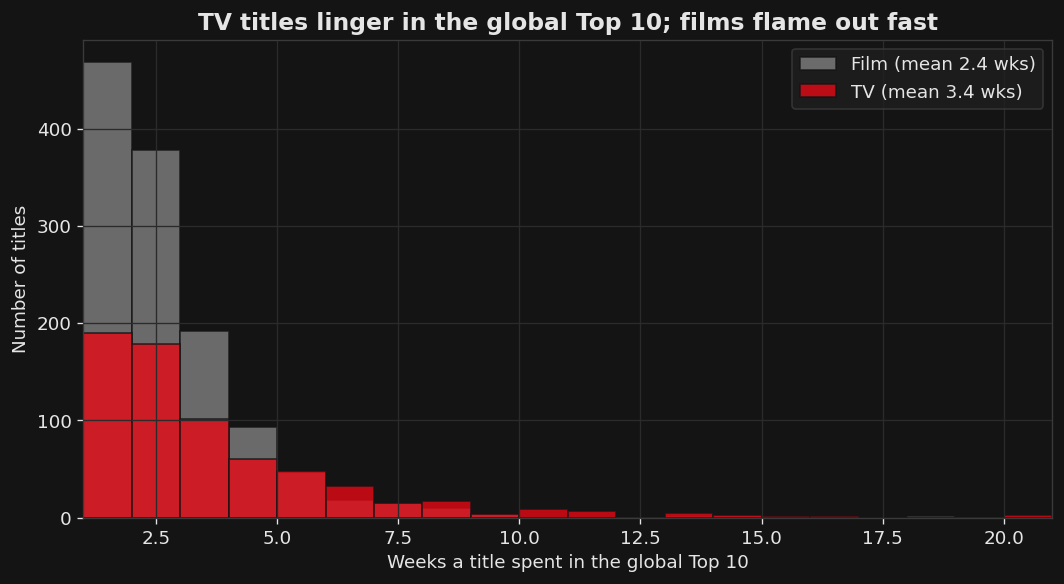

Share lasting >=5 weeks  Film: 8.6%  TV: 22.5%


In [ ]:
# ---- How long do titles linger in the global Top 10? ----
gt = g.groupby(["show_title","type"])["cumulative_weeks_in_top_10"].max().reset_index()
fig, ax = plt.subplots(figsize=(9,5))
bins = np.arange(1, 22)
# Plot histograms for Film and TV
for t, col in [("Film",FILM),("TV",TV)]:
    ax.hist(gt[gt.type==t]["cumulative_weeks_in_top_10"], bins=bins, alpha=.8,
            label=f"{t} (mean {gt[gt.type==t]['cumulative_weeks_in_top_10'].mean():.1f} wks)",
            color=col, edgecolor=INK)
ax.set_title("TV titles linger in the global Top 10; films flame out fast")
ax.set_xlabel("Weeks a title spent in the global Top 10"); ax.set_ylabel("Number of titles")
ax.legend(facecolor=PANEL, edgecolor="#3a3a3a", labelcolor=LIGHT)
ax.set_xlim(1,21); plt.tight_layout(); plt.savefig(f"{OUT}/01_staying_power_dist.png", bbox_inches="tight"); plt.show()
print("Share lasting >=5 weeks  Film: {:.1%}  TV: {:.1%}".format(
    (gt[gt.type=='Film']['cumulative_weeks_in_top_10']>=5).mean(),
    (gt[gt.type=='TV']['cumulative_weeks_in_top_10']>=5).mean()))

### Visual 2 — The marathon titles are almost all serialized TV

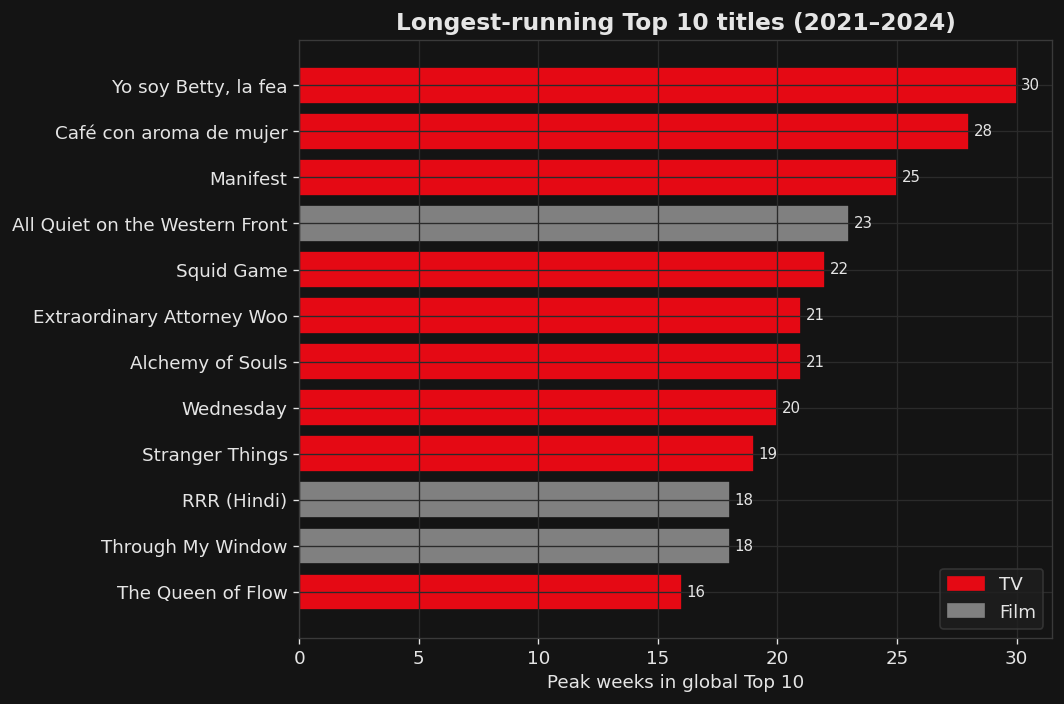

In [ ]:
# ---- Longest-running Top 10 titles (2021–2024) ----
top = (g.groupby(["show_title","category","type"])["cumulative_weeks_in_top_10"].max()
         .reset_index().sort_values("cumulative_weeks_in_top_10").tail(12))
fig, ax = plt.subplots(figsize=(9,6))
colors = [TV if t=="TV" else FILM for t in top.type]
# Plot horizontal bar chart
ax.barh(top.show_title, top.cumulative_weeks_in_top_10, color=colors, edgecolor=INK)
# Add text labels to the bars
for y,(v,cat) in enumerate(zip(top.cumulative_weeks_in_top_10, top.category)):
    ax.text(v+0.2, y, f"{int(v)}", va="center", color=LIGHT, fontsize=9)
ax.set_title("Longest-running Top 10 titles (2021–2024)")
ax.set_xlabel("Peak weeks in global Top 10")
from matplotlib.patches import Patch
# Add legend for TV and Film
ax.legend(handles=[Patch(color=TV,label="TV"),Patch(color=FILM,label="Film")],
          facecolor=PANEL, edgecolor="#3a3a3a", labelcolor=LIGHT, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/02_top_runners.png", bbox_inches="tight"); plt.show()

### Visual 3 — All-time demand: TV pulls 3.6× the first-91-day hours of film

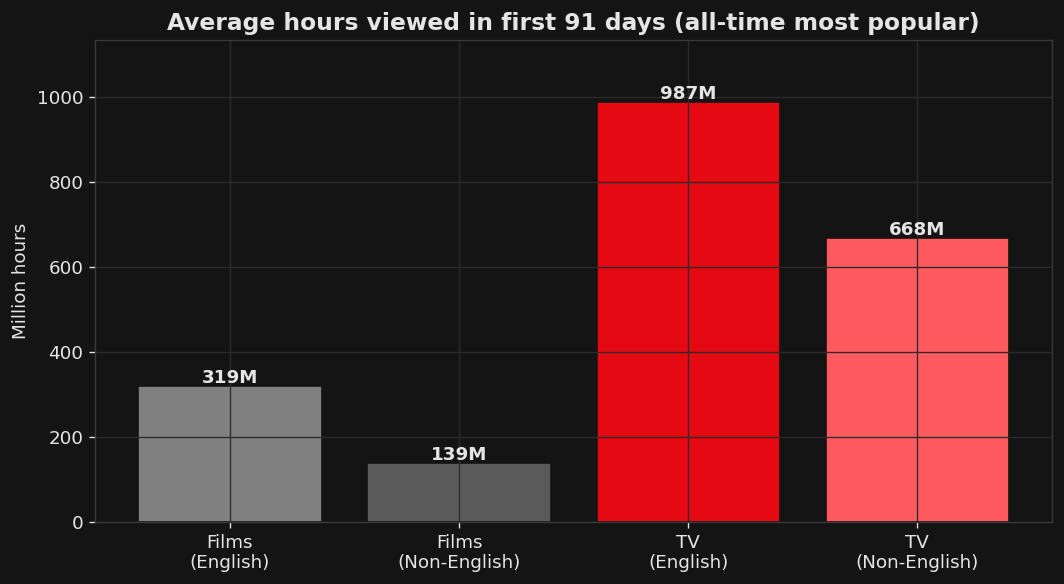

TV / Film multiple: 3.6


In [ ]:
# ---- Average hours viewed in first 91 days (all-time most popular) ----
order=["Films (English)","Films (Non-English)","TV (English)","TV (Non-English)"]
# Calculate average hours viewed by category and reindex to desired order
ph = m.groupby("category")["hours_viewed_first_91_days"].mean().reindex(order)/1e6
fig, ax = plt.subplots(figsize=(9,5))
cols=[FILM,"#5a5a5a",TV,"#ff5a5f"]
# Plot bar chart for average hours viewed
ax.bar(range(len(ph)), ph.values, color=cols, edgecolor=INK)
ax.set_xticks(range(len(ph))); ax.set_xticklabels([o.replace(" (","\n(") for o in order])
# Add text labels above bars
for i,v in enumerate(ph.values): ax.text(i, v+8, f"{v:,.0f}M", ha="center", color=LIGHT, fontweight="bold")
ax.set_title("Average hours viewed in first 91 days (all-time most popular)")
ax.set_ylabel("Million hours"); ax.set_ylim(0, ph.max()*1.15)
plt.tight_layout(); plt.savefig(f"{OUT}/03_popular_hours.png", bbox_inches="tight"); plt.show()
# Print ratio of average hours viewed for TV vs Film
print("TV / Film multiple:", round(m[m.type=='TV'].hours_viewed_first_91_days.mean()/m[m.type=='Film'].hours_viewed_first_91_days.mean(),1))

### Visual 4 — Country durability: TV is held ~2.3× longer than film, everywhere

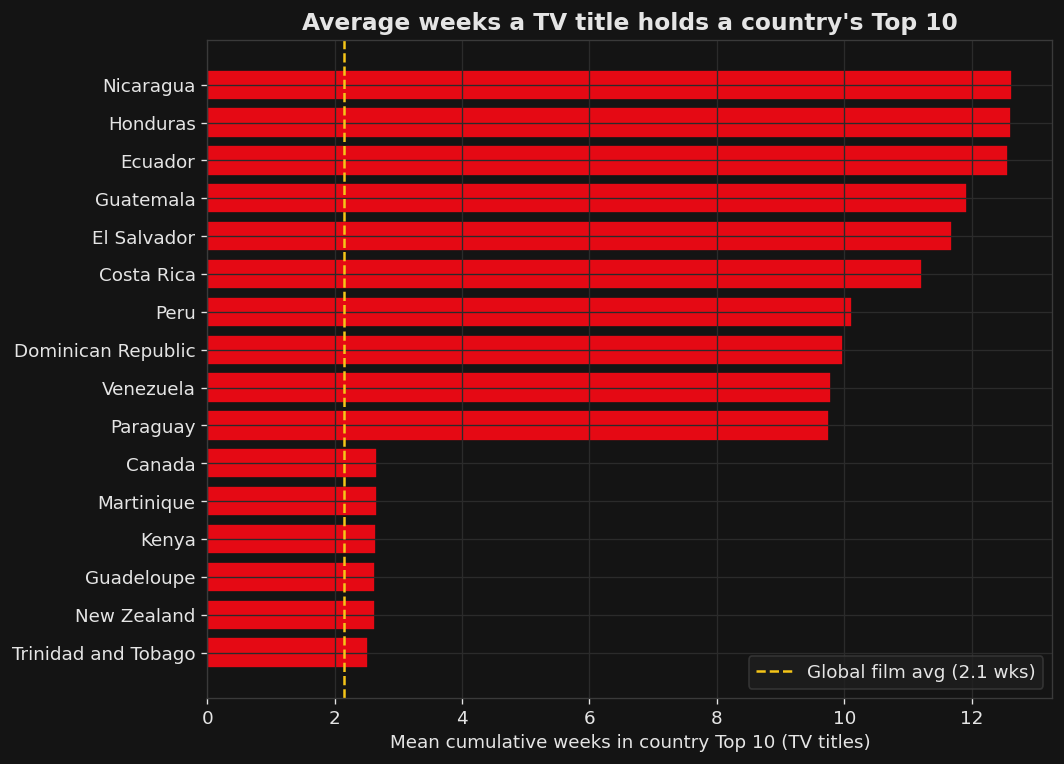

Country TV avg: 4.8 | Film avg: 2.1


In [ ]:
# ---- Average weeks a TV title holds a country's Top 10 ----
ctv = c[c.type=="TV"].groupby("country_name")["cumulative_weeks_in_top_10"].mean().sort_values()
sel = pd.concat([ctv.head(6), ctv.tail(10)])
fig, ax = plt.subplots(figsize=(9,6.5))
# Plot horizontal bar chart for average weeks in Top 10 by country
ax.barh(sel.index, sel.values, color=TV, edgecolor=INK)
# Calculate global film average for comparison
film_avg = c[c.type=='Film']['cumulative_weeks_in_top_10'].mean()
# Add vertical line for global film average
ax.axvline(film_avg, color=GOLD, ls="--", lw=1.5, label=f"Global film avg ({film_avg:.1f} wks)")
ax.set_title("Average weeks a TV title holds a country's Top 10")
ax.set_xlabel("Mean cumulative weeks in country Top 10 (TV titles)")
ax.legend(facecolor=PANEL, edgecolor="#3a3a3a", labelcolor=LIGHT, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/04_country_durability.png", bbox_inches="tight"); plt.show()
# Print average weeks in Top 10 for TV and Film
print("Country TV avg:", round(c[c.type=='TV'].cumulative_weeks_in_top_10.mean(),1),
      "| Film avg:", round(film_avg,1))

### Visual 5 — Durability gap is persistent, not a one-off spike

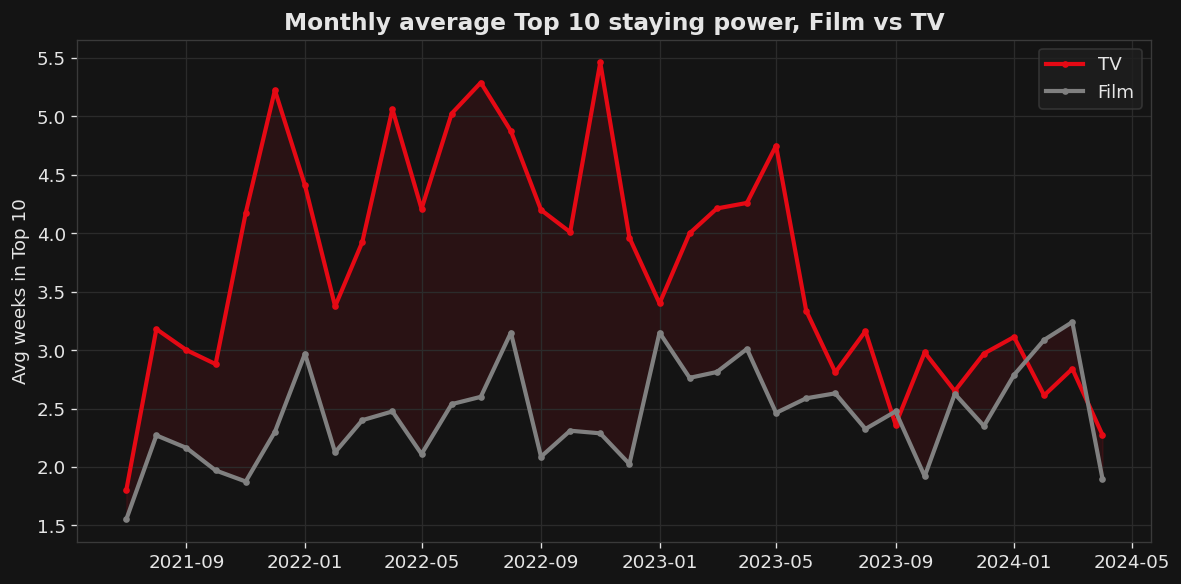

In [ ]:
# ---- Monthly average Top 10 staying power, Film vs TV ----
g["month"]=g.week.dt.to_period("M").dt.to_timestamp()
tr=g.groupby(["month","type"])["cumulative_weeks_in_top_10"].mean().unstack()
fig, ax = plt.subplots(figsize=(10,5))
# Plot line charts for TV and Film average weeks in Top 10
ax.plot(tr.index, tr["TV"], color=TV, lw=2.5, marker="o", ms=3, label="TV")
ax.plot(tr.index, tr["Film"], color=FILM, lw=2.5, marker="o", ms=3, label="Film")
# Fill area between Film and TV lines to visualize the difference
ax.fill_between(tr.index, tr["Film"], tr["TV"], color=TV, alpha=.10)
ax.set_title("Monthly average Top 10 staying power, Film vs TV")
ax.set_ylabel("Avg weeks in Top 10"); ax.set_xlabel("")
ax.legend(facecolor=PANEL, edgecolor="#3a3a3a", labelcolor=LIGHT)
plt.tight_layout(); plt.savefig(f"{OUT}/05_trend.png", bbox_inches="tight"); plt.show()

### Visual 6 — The most durable quadrant is Non-English TV

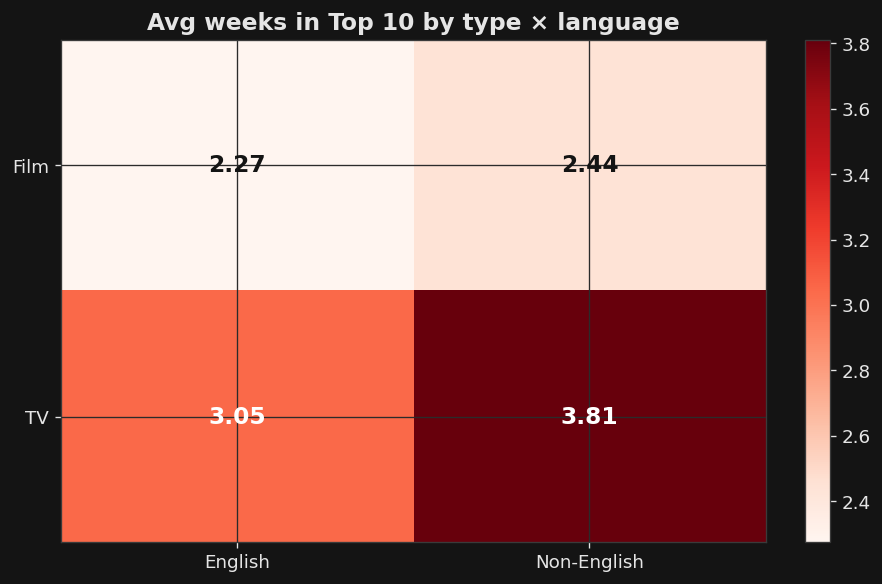

lang  English  Non-English
type                      
Film     2.27         2.44
TV       3.05         3.81


In [ ]:
# ---- Average weeks in Top 10 by type × language ----
mat = (g.groupby(["show_title","type","lang"])["cumulative_weeks_in_top_10"].max()
         .reset_index().groupby(["type","lang"])["cumulative_weeks_in_top_10"].mean()
         .unstack())[["English","Non-English"]]
fig, ax = plt.subplots(figsize=(7.5,5))
# Create heatmap for average weeks in Top 10 by type and language
im = ax.imshow(mat.values, cmap="Reds", aspect="auto")
ax.set_xticks([0,1]); ax.set_xticklabels(["English","Non-English"])
ax.set_yticks([0,1]); ax.set_yticklabels(mat.index)
# Add text annotations to each cell in the heatmap
for i in range(2):
    for j in range(2):
        ax.text(j,i,f"{mat.values[i,j]:.2f}", ha="center", va="center",
                color="white" if mat.values[i,j]>3 else INK, fontweight="bold", fontsize=14)
ax.set_title("Avg weeks in Top 10 by type × language")
# Add colorbar to the heatmap
cb=plt.colorbar(im, fraction=.046); cb.ax.tick_params(colors=LIGHT)
plt.tight_layout(); plt.savefig(f"{OUT}/06_lang_matrix.png", bbox_inches="tight"); plt.show()
print(mat.round(2))

### Visual 7 (bonus) — Reach: titles that charted in all 94 countries

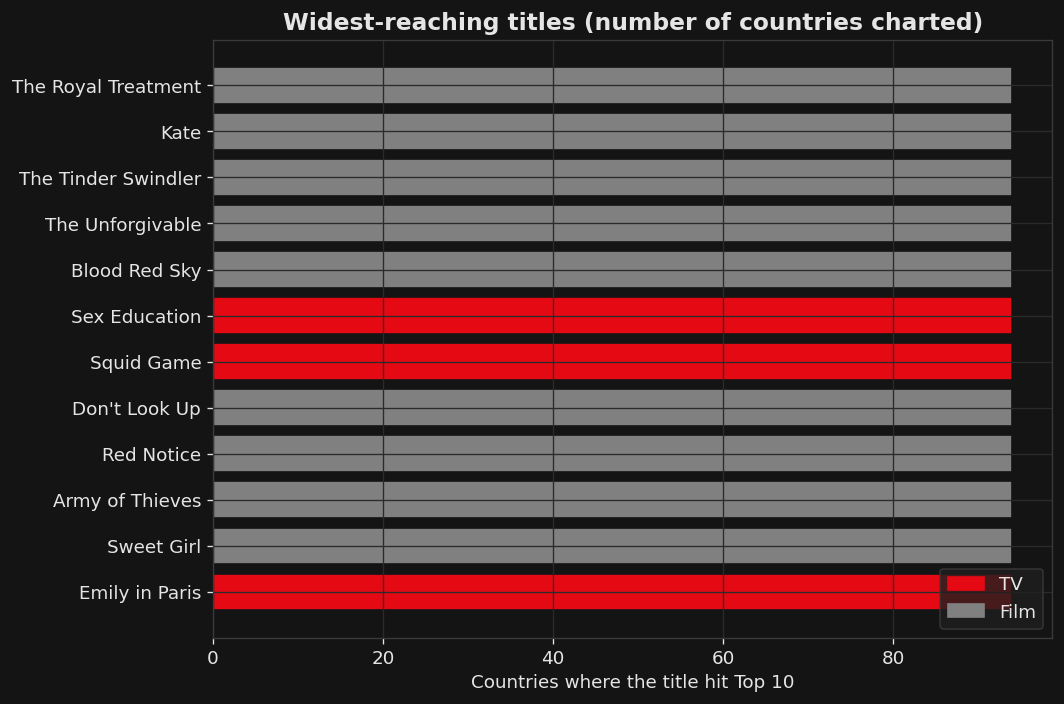

In [ ]:
# --- Widest-reaching titles (number of countries charted) ----
reach = (c.groupby(["show_title","type"])["country_name"].nunique()
           .reset_index().sort_values("country_name").tail(12))
fig, ax = plt.subplots(figsize=(9,6))
# Plot horizontal bar chart for widest-reaching titles
ax.barh(reach.show_title, reach.country_name,
        color=[TV if t=="TV" else FILM for t in reach.type], edgecolor=INK)
ax.set_title("Widest-reaching titles (number of countries charted)")
ax.set_xlabel("Countries where the title hit Top 10")
from matplotlib.patches import Patch
# Add legend for TV and Film
ax.legend(handles=[Patch(color=TV,label="TV"),Patch(color=FILM,label="Film")],
          facecolor=PANEL, edgecolor="#3a3a3a", labelcolor=LIGHT, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/07_reach.png", bbox_inches="tight"); plt.show()

## Bottom line & recommendation
- **Opening week is a tie.** Films and TV split the weekly #1 slot 50/50. films are excellent at the loud launch.
- **The long tail belongs to TV.** TV titles are **~2.6× more likely to last five weeks or more** in the global Top 10, hold a country's Top 10 for **4.8 weeks vs 2.1** for film, and pull **3.6× the first-91-day hours** among all-time hits.
- **Non-English TV is the single most durable quadrant** and travels widely across all 94 markets.

**Call to action:** Reallocate a defined slice of marginal content budget from one-off films toward returnable, non-English serialized TV. Durable Top 10 presence is the engagement moat that reduces churn, and the data indicates serialized international TV builds it most efficiently.